# Detection ROC curves

Your companion search over a grid of positions and fluxes returns a best candidate with a $\Delta\chi^2$ of, say, 20. Is it real? And if the search finds nothing convincing, how faint a companion could it have found? Both questions have frequentist answers that you can compute by simulation for your own observation and grid with [`virgil.detection`](api/detection.md).

Three terms carry the page. The **false-alarm probability (FAP)** of a threshold is the fraction of companion-free observations in which the search would still reach it; the FAP of an observed value is the p-value of the search, the probability that noise alone would give a candidate at least as strong somewhere on the grid. The **completeness**, or true-positive rate, is the fraction of real companions of a given flux and separation found above the threshold. A **ROC curve** (receiver operating characteristic) plots completeness against FAP as the threshold slides from strict to loose, showing the whole trade-off between false alarms and missed companions at once.

You should come away with three things. First, the look-elsewhere effect: Wilks's theorem turns $\Delta\chi^2$ into a significance for one position chosen in advance, but the best of hundreds of positions is much larger than any one, so a search must take its threshold from simulations of companion-free data over the same grid. Second, what to quote for a detection: the empirical FAP of the observed statistic, with its uncertainty. Third, what to quote for a non-detection: the contrast at which the search is 50% and 90% complete at a stated FAP, beside the Absil and Ruffio limits of the [contrast limits](contrast_limits.md) tutorial.

## Setup

We simulate the 7-hole NIRISS aperture mask at 4.3 µm with [`nrm_oidata`](api/coverage.md#virgil.coverage.nrm_oidata): 21 squared visibilities with errors of 0.01 and 35 closure phases with errors of 0.5°. The longest baseline is about 5.3 m, so the resolution $\lambda/B$ is about 170 mas. The star is a point source, so the **null scene**, the scene without a companion, is a `BinaryModelCartesian` with companion flux zero. That is the null hypothesis every statistic here tests.

The search grid covers ±120 mas in both coordinates in steps of 16 mas, about $\lambda/(10B)$: fine enough that a companion between grid points loses at most a few per cent of its $\Delta\chi^2$ and is found near its true position, where a much coarser grid can put the best match on the wrong point. The even number of points keeps the star's own position, where a companion is indistinguishable from the star, off the grid. The flux axis has 32 values spaced logarithmically from $3\times10^{-4}$ to $3\times10^{-2}$ (companion/primary). It seeds the optimizer that refines the best flux at each position, and it is the prior of the log Bayes factor, uniform in log flux between its ends. We claim detections at an FAP of 0.135%, the one-sided Gaussian tail at 3σ: one-sided because a flux cannot be negative, so only upward fluctuations count (the often quoted 0.27% is two-sided).

In [1]:
import jax
import jax.numpy as jnp
import numpy as onp
from scipy import stats

from virgil.coverage import nrm_oidata
from virgil.detection import (
    detection_statistics,
    gaussian_null,
    injection_grid,
    injection_recovery,
    local_nsigma,
    rescale_errors,
)
from virgil.grid_fit import laplace_flux_uncertainty_grid, optimized_flux_grid
from virgil.limits import absil_limits, flux_to_delta_mag, ruffio_upperlimit
from virgil.models import BinaryModelCartesian
from virgil.plotting import (
    plot_completeness,
    plot_contrast_curve,
    plot_null_distribution,
    plot_roc,
    set_style,
)

set_style()  # the figure style used throughout the docs

template = nrm_oidata()  # 21 V² and 35 closure phases, no values yet
null_scene = BinaryModelCartesian(dra=0.0, ddec=0.0, flux=0.0)  # star alone
grid = {
    "dra": jnp.linspace(-120.0, 120.0, 16),  # mas, steps of 16 mas
    "ddec": jnp.linspace(-120.0, 120.0, 16),
    "flux": jnp.geomspace(3e-4, 3e-2, 32),
}
FAP = stats.norm.sf(3.0)  # 0.135%: the one-sided tail at 3 sigma

print(
    f"{template.vis.size} V² and {template.phi.size} closure phases; "
    f"{grid['dra'].size * grid['ddec'].size} positions × "
    f"{grid['flux'].size} fluxes; FAP = {FAP:.3%}"
)

21 V² and 35 closure phases; 256 positions × 32 fluxes; FAP = 0.135%


## A candidate

Here is the observation to judge: a companion of flux $5\times10^{-3}$ (Δmag 5.75) at 70 mas and position angle 60°, plus noise drawn from the errors, searched with [`detection_statistics`](api/detection.md#virgil.detection.detection_statistics). The search returns the best companion's position and flux and three statistics of how strongly the data prefer a companion to none. $\Delta\chi^2$ is twice the log-likelihood gain of the best companion on the grid over none, with its flux refined and non-negative. The log Bayes factor $\log B$ is the natural log of the likelihood ratio averaged over the grid, the evidence for "a companion somewhere on the grid" against "no companion". The maximum SNR is the largest best-fit flux over its uncertainty, over positions.

[`local_nsigma`](api/detection.md#virgil.detection.local_nsigma) converts $\Delta\chi^2$ to a significance with Wilks's theorem. It is a **local** significance: what the candidate would have if we had looked only at that position, chosen before seeing the data.

In [2]:
truth = BinaryModelCartesian(dra=60.6, ddec=35.0, flux=5e-3)  # 70 mas, PA 60°
observed = template.with_model(truth, key=jax.random.PRNGKey(2026))
obs = detection_statistics(BinaryModelCartesian, observed, grid)

print(
    f"best companion at ΔRA = {float(obs['dra']):.0f} mas, "
    f"ΔDec = {float(obs['ddec']):.0f} mas, flux = {float(obs['flux']):.2e} "
    f"(truth: 60.6 mas, 35.0 mas, 5.00e-03)\n"
    f"Δχ² = {float(obs['delta_chi2']):.1f} "
    f"(local significance {float(local_nsigma(obs['delta_chi2'])):.1f}σ), "
    f"log B = {float(obs['log_bayes_factor']):.1f}, "
    f"max SNR = {float(obs['max_snr']):.1f}"
)

best companion at ΔRA = 88 mas, ΔDec = 40 mas, flux = 4.85e-03 (truth: 60.6 mas, 35.0 mas, 5.00e-03)
Δχ² = 31.8 (local significance 5.6σ), log B = 11.0, max SNR = 5.6


## Simulating the search

To learn how often noise alone gives so large a $\Delta\chi^2$, and how often a real companion is found, we repeat the search on simulated observations with [`injection_recovery`](api/detection.md#virgil.detection.injection_recovery). It simulates `n_null` companion-free **null draws**, with Gaussian noise from the template's errors ([`gaussian_null`](api/detection.md#virgil.detection.gaussian_null)), and one observation per companion in `injections`, here from [`injection_grid`](api/detection.md#virgil.detection.injection_grid): 4 separations from 40 to 100 mas times 8 fluxes from $10^{-3}$ to $3\times10^{-2}$, each at 40 random position angles. One compiled function searches every simulation exactly as the real data were searched, and returns a [`DetectionMC`](api/detection.md#virgil.detection.DetectionMC), a plain NumPy container from which everything below is computed.

With 10,000 null draws, about 13 lie above the 0.135% threshold and pin it down; `draw_batch=32` searches 32 draws at once, which keeps a GPU busy. To split a larger run over cluster array jobs with different seeds, `save` each result and merge them with `DetectionMC.concatenate`.

In [3]:
FLUXES = onp.geomspace(1e-3, 3e-2, 8)
injections = injection_grid([40.0, 60.0, 80.0, 100.0], FLUXES, n_pa=40, key=1)

mc = injection_recovery(
    BinaryModelCartesian,
    null_scene,
    template,
    grid,
    key=0,
    n_null=10_000,
    injections=injections,
    draw_batch=32,
    progress=False,
)
print(f"{mc.n_null} null and {mc.n_injected} injected searches")

10000 null and 1280 injected searches


## The look-elsewhere effect

For each threshold on the x-axis, the plot shows the fraction of the 10,000 companion-free searches that reached it: its false-alarm probability. The dashed black curve is Wilks's prediction at one position fixed in advance, where $\Delta\chi^2$ is zero half the time (whenever the best flux would be negative) and $\chi^2_1$ otherwise, so the FAP is $\frac{1}{2}P(\chi^2_1 \geq \Delta\chi^2)$.

The grid search's curve lies far above it. Each of the 256 positions is another chance for noise to mimic a companion, and the search reports the best; neighbouring positions are correlated, so the effect is smaller than for 256 independent tries, but still large. The dotted horizontal line is our FAP of 0.135%. Wilks's curve crosses it at $\Delta\chi^2 = 9$, the local 3σ; the simulations cross it at a much higher empirical threshold, the dashed blue line. The red point is our candidate, at its $\Delta\chi^2$ and FAP with a 95% interval.

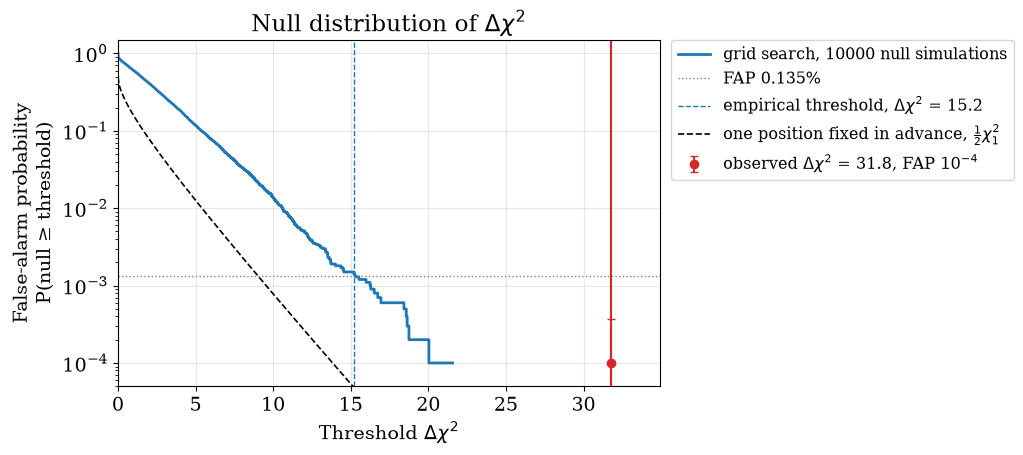

In [4]:
plot_null_distribution(
    mc, "delta_chi2", observed=obs["delta_chi2"], fap=FAP
);

## What to quote for a detection

[`threshold`](api/detection.md#virgil.detection.DetectionMC.threshold) gives the $\Delta\chi^2$ that 0.135% of null searches exceed, with a bootstrap error from the finite number of draws. [`false_alarm_probability`](api/detection.md#virgil.detection.DetectionMC.false_alarm_probability) gives any value's FAP as $(k+1)/(n+1)$, where $k$ of the $n$ null draws reach it, with an exact binomial 95% interval. We print the FAP of Wilks's local 3σ threshold, to show how optimistic the local significance is over a grid, and the candidate's FAP, converted back through the one-sided Gaussian tail to a **global** significance for the search as a whole. If no null draw reaches the candidate, its FAP is only an upper limit set by the number of draws, and its global significance a lower limit; more draws sharpen both.

For a detection, quote the observed $\Delta\chi^2$, its empirical FAP with the interval and the number of null draws, and the global significance it implies, and say what was simulated: the grid, the noise model and the errors. Give the Wilks significance too if you like, but always label it local.

In [5]:
threshold, error = mc.threshold("delta_chi2", FAP)
wilks_fap = mc.false_alarm_probability("delta_chi2", 9.0)[0]
fap, low, high = mc.false_alarm_probability("delta_chi2", obs["delta_chi2"])
bound = "≥ " if low == 0.0 else ""  # no null draw reached the candidate

print(
    f"threshold at FAP {FAP:.3%}: Δχ² = {threshold:.1f} ± {error:.1f} "
    f"(Wilks, at one position: 9)\n"
    f"Wilks's Δχ² = 9 has an FAP of {wilks_fap:.1%} over the grid\n"
    f"candidate: Δχ² = {float(obs['delta_chi2']):.1f}, FAP = {fap:.2g} "
    f"(95%: {low:.2g} to {high:.2g}), global significance "
    f"{bound}{stats.norm.isf(fap):.1f}σ "
    f"(local {float(local_nsigma(obs['delta_chi2'])):.1f}σ)"
)

threshold at FAP 0.135%: Δχ² = 15.2 ± 0.9 (Wilks, at one position: 9)
Wilks's Δχ² = 9 has an FAP of 2.2% over the grid
candidate: Δχ² = 31.8, FAP = 0.0001 (95%: 0 to 0.00037), global significance ≥ 3.7σ (local 5.6σ)


## ROC curves: which statistic?

Every simulation gives all three statistics, so their ROC curves compare fairly. We draw them for injections of flux $4.3\times10^{-3}$ (Δmag 5.9), the fourth of our eight fluxes, at all four separations together. Each curve runs from a strict threshold (lower left) to a loose one (upper right). The false-positive axis is logarithmic because detections are claimed at small FAPs, so the grey chance curve, TPR = FPR (no better than a coin toss), is curved. The dotted vertical line is the FAP that Wilks's theorem assigns to a local 3σ, and the circle on each curve marks where its threshold equals a local 3σ ($\Delta\chi^2 = 9$, or an SNR of 3); the horizontal gap between them is the look-elsewhere effect again. A ROC curve depends only on how a statistic ranks the simulations, not on its scale, so such different statistics can share a plot.

The $\Delta\chi^2$ and maximum-SNR curves practically coincide. For a faint companion the log likelihood is nearly quadratic in flux, so $\Delta\chi^2 \approx \mathrm{SNR}^2$ wherever the best flux is positive, both statistics pick the same best position, and they rank the simulations in the same order. The log Bayes factor averages the likelihood over all positions and fluxes instead of taking the best, so it can rank them differently; the plot shows whether that helps here.

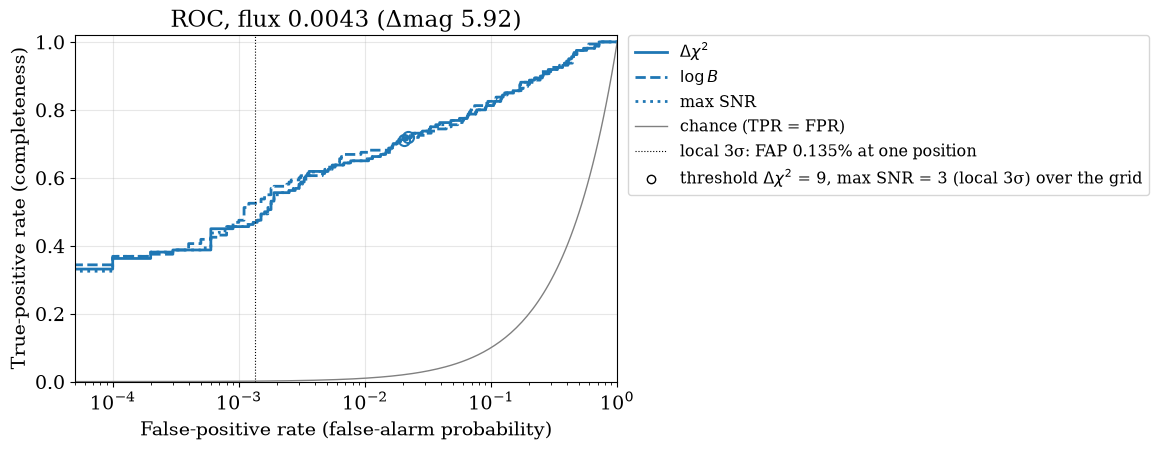

In [6]:
plot_roc(
    mc, ["delta_chi2", "log_bayes_factor", "max_snr"], flux=FLUXES[3]
);

## What to quote for a non-detection

After a non-detection, ask what the search could have found. [`completeness`](api/detection.md#virgil.detection.DetectionMC.completeness) gives, for each injected separation and flux, the fraction detected above the calibrated threshold, and [`contrast_curve`](api/detection.md#virgil.detection.DetectionMC.contrast_curve) interpolates in flux to the contrast where that fraction reaches a chosen level. These are empirical contrast curves: at the 90% contrast, nine companions in ten would have been detected at an FAP of 0.135%, look-elsewhere effect included. The table gives them in Δmag at each injected separation (NaN where the injected fluxes do not span that completeness).

In [7]:
sep, flux50 = mc.contrast_curve("delta_chi2", FAP, completeness=0.5)
_, flux90 = mc.contrast_curve("delta_chi2", FAP, completeness=0.9)

print(f"Δmag reached at FAP {FAP:.3%}\nsep (mas)  50% complete  90% complete")
for s, f50, f90 in zip(sep, flux50, flux90):
    print(
        f"{s:9.0f}{float(flux_to_delta_mag(f50)):14.2f}"
        f"{float(flux_to_delta_mag(f90)):14.2f}"
    )

Δmag reached at FAP 0.135%
sep (mas)  50% complete  90% complete
       40          4.81          4.36
       60          5.80          5.21
       80          6.09          5.55
      100          6.44          5.65


The map shows the completeness behind those curves, cell by cell, with the 50% and 90% curves on it. Over it are the Absil and Ruffio limits of a companion-free observation, as in the [contrast limits](contrast_limits.md) tutorial, which answer different questions. Ruffio's limit, at the 3σ-equivalent percentile, is a Bayesian upper limit on the flux at each position, given a companion exactly there. Absil's, at 3σ, is the flux that a $\chi^2$ test against the no-companion model rejects at each position. Neither involves a detection threshold or the look-elsewhere effect, and each comes from one noise realization and wanders with it, while the completeness curves average over many simulated observations.

For a non-detection, quote the 50% and 90% completeness contrasts at a stated FAP ("the search is 90% complete to Δmag X at 80 mas, at a false-alarm probability of 0.135%"), with the grid, noise model and number of injections. Give Absil or Ruffio limits alongside for comparison with the literature.

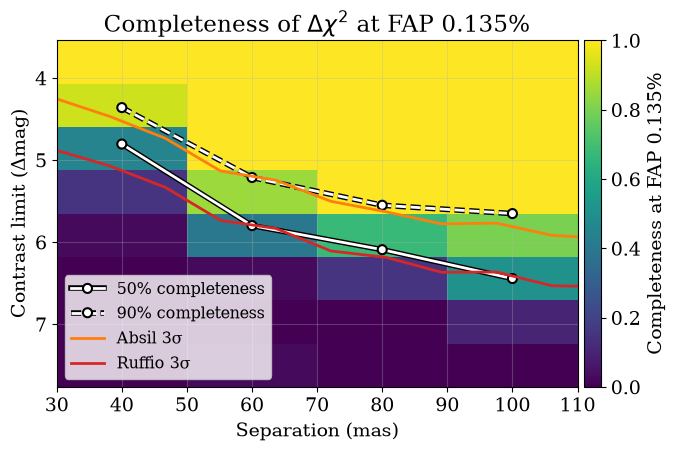

In [8]:
blank = template.with_model(null_scene, key=jax.random.PRNGKey(7))
absil = absil_limits(BinaryModelCartesian, blank, grid, sigma=3.0)
best = optimized_flux_grid(BinaryModelCartesian, blank, grid)
sigma = laplace_flux_uncertainty_grid(BinaryModelCartesian, blank, grid, best)
ruffio = ruffio_upperlimit(best, sigma, stats.norm.cdf(3.0))

fig, ax = plot_completeness(mc, "delta_chi2", FAP)
for limit, label, color in [(absil, "Absil 3σ", "C1"), (ruffio, "Ruffio 3σ", "C3")]:
    plot_contrast_curve(limit, grid, label=label, color=color, band=False, ax=ax)
ax.legend(loc="lower left", fontsize="small");

## When the error bars are wrong

So far the errors were right by construction, since the null draws were simulated from them. Suppose instead the real noise is 1.5 times the quoted errors, as is common for calibrated interferometric data. The Gaussian null still simulates the quoted errors, so its threshold is too low, and its true FAP, measured on 2000 simulations with the real noise, is far above nominal.

Two tools repair this. [`rescale_errors`](api/detection.md#virgil.detection.rescale_errors) estimates the factor from the data, scaling the errors so the null scene has $\chi^2_r = 1$, separately for the V² and closure phases; with rescaled errors the Gaussian calibration holds again. [`bootstrap_null`](api/detection.md#virgil.detection.bootstrap_null) (`noise="bootstrap"`) does not trust the errors at all: it builds null draws by flipping the signs of the data's own whitened residuals about the null scene, so the draws carry the real noise. The table compares the threshold at an FAP of 1% (looser than 0.135%, so 2000 draws measure it well) from honest errors, from wrong errors with a Gaussian null, and from wrong errors with a bootstrap null of one companion-free observation, each with the true FAP of its threshold.

In [9]:
real_noise = gaussian_null(null_scene, template, error_scale=1.5)
bad = real_noise(jax.random.PRNGKey(11))  # companion-free, errors too small
truth_mc = injection_recovery(  # what the wrong errors really give
    BinaryModelCartesian, null_scene, template, grid, key=2,
    n_null=2000, noise=real_noise, draw_batch=32, progress=False,
)
boot_mc = injection_recovery(  # calibrated on the data's own residuals
    BinaryModelCartesian, null_scene, bad, grid, key=3,
    n_null=2000, noise="bootstrap", draw_batch=32, progress=False,
)
factors = rescale_errors(null_scene, bad)[1]

print(
    f"rescale_errors factors: V² {factors['vis']:.2f}, "
    f"closure phases {factors['phi']:.2f} (truth 1.5)\n"
    f"{'threshold at FAP 1% from':<36}{'Δχ²':>6}{'true FAP':>10}"
)
for label, calibration, actual in [
    ("honest errors, Gaussian null", mc, mc),
    ("errors 1.5× too small, Gaussian null", mc, truth_mc),
    ("errors 1.5× too small, bootstrap", boot_mc, truth_mc),
]:
    t = calibration.threshold("delta_chi2", 0.01)[0]
    p = actual.false_alarm_probability("delta_chi2", t)[0]
    print(f"{label:<36}{t:6.1f}{p:10.1%}")

rescale_errors factors: V² 1.31, closure phases 1.78 (truth 1.5)
threshold at FAP 1% from               Δχ²  true FAP
honest errors, Gaussian null          10.6      1.0%
errors 1.5× too small, Gaussian null  10.6     14.5%
errors 1.5× too small, bootstrap      23.8      0.9%


## Summary

A companion search reports the best of many positions, so calibrate its statistic against simulated companion-free searches over the same grid; `local_nsigma` gives only the local Wilks significance at one position, which over a grid overstates the significance. `injection_recovery` runs the null and injected searches in one call, and its `DetectionMC` gives thresholds, false-alarm probabilities, ROC curves, completeness maps and contrast curves, drawn by `plot_null_distribution`, `plot_roc` and `plot_completeness`.

For a **detection**, quote the observed $\Delta\chi^2$ with its empirical false-alarm probability, 95% interval and number of null draws, and the global significance that FAP implies; give the Wilks significance only if labelled local. For a **non-detection**, quote the contrasts at which the search is 50% and 90% complete at a stated FAP (0.135%, the one-sided 3σ, is a common choice), with Absil or Ruffio limits alongside if you like.

Three caveats. The nuisance parameters, here the null scene, are held at their values for the real data rather than refitted for every simulation. The grid must be fine enough that companions are found near their true positions, and the calibration holds only for the grid it was simulated on. And a Gaussian null is only as good as the error bars: if they may be wrong, rescale them with `rescale_errors` or calibrate with a residual bootstrap (`noise="bootstrap"`), remembering that the bootstrap needs a null scene that fits the data.